## **1.** **IPL Match Performance & Strategic Analysis Using Python**

 **Project Overview**

This project analyses IPL match-level data from 2008 to 2019 to identify team performance patterns, toss-related trends, venue insights, match outcomes, and Player of the Match achievements.

**Tools & Technologies**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Google Colab

**Dataset**

756 IPL match records with 18 columns.

In [659]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [660]:
df=pd.read_excel("/content/IPL_Matches_Data Analysis.xlsx")

In [661]:
df

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,IPL-2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,IPL-2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A d Kishore,S Ravi,NaN
2,3,IPL-2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK dan,NaN
3,4,IPL-2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,IPL-2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,11347,IPL-2019,Mumbai,2019-05-05,Kolkata Knight Riders,Mumbai Indians,Mumbai Indians,field,normal,0,Mumbai Indians,0,9,HH Pandya,Wankhede Stadium,da Kishore,O dan,S Ravi
752,11412,IPL-2019,Chennai,2019-05-07,Chennai Super Kings,Mumbai Indians,Chennai Super Kings,bat,normal,0,Mumbai Indians,0,6,AS Yadav,M. A. Chidambaram Stadium,Nigel Llong,Nitin Menon,Ian Gould
753,11413,IPL-2019,Visakhapatnam,2019-05-08,Sunrisers Hyderabad,Delhi Capitals,Delhi Capitals,field,normal,0,Delhi Capitals,0,2,RR Pant,ACA-VDCA Stadium,NaN,NaN,NaN
754,11414,IPL-2019,Visakhapatnam,2019-05-10,Delhi Capitals,Chennai Super Kings,Chennai Super Kings,field,normal,0,Chennai Super Kings,0,6,F du Plessis,ACA-VDCA Stadium,Sundaram Ravi,Bruce Oxenford,Chettithody Shamshuddin


In [662]:
df.head()

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,IPL-2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",AY Dandekar,NJ Llong,NaN
1,2,IPL-2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,A d Kishore,S Ravi,NaN
2,3,IPL-2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK dan,NaN
3,4,IPL-2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,AK Chaudhary,C Shamshuddin,NaN
4,5,IPL-2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M Chinnaswamy Stadium,NaN,NaN,NaN


In [663]:
df.columns

Index(['id', 'Season', 'city', 'date', 'Team1', 'Team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2',
       'umpire3'],
      dtype='object')

In [664]:
df.shape


(756, 18)

In [665]:
df.sample(5)

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
727,11323,IPL-2019,Mohali,2019-04-16,Kings XI Punjab,Rajasthan Royals,Rajasthan Royals,field,normal,0,Kings XI Punjab,12,0,R Ashwin,IS Bindra Stadium,Anil Chaudhary,Vineet Kulkarni,S Ravi
359,360,IPL-2012,Mumbai,2012-05-09,Mumbai Indians,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,9,CH Gayle,Wankhede Stadium,BF Bowden,VA Kulkarni,NaN
598,599,IPL-2016,Delhi,2016-04-27,Gujarat Lions,Delhi Daredevils,Delhi Daredevils,field,normal,0,Gujarat Lions,1,0,CH Morris,Feroz Shah Kotla,M Erasmus,S Ravi,NaN
571,572,IPL-2015,Hyderabad,2015-05-17,Sunrisers Hyderabad,Mumbai Indians,Sunrisers Hyderabad,bat,normal,0,Mumbai Indians,0,9,MJ McClenaghan,"Rajiv Gandhi International Stadium, Uppal",CB Gaffaney,K Srinath,NaN
145,146,IPL-2009,Durban,2009-05-05,Kolkata Knight Riders,Delhi Daredevils,Kolkata Knight Riders,bat,normal,0,Delhi Daredevils,0,9,G Gambhir,Kingsmead,GAV Baxter,IL Howell,NaN


In [666]:
df.describe()

,id,date,dl_applied,win_by_runs,win_by_wickets
count,756.000000,756,756.000000,756.000000,756.000000
mean,1792.178571,2013-10-07 06:22:51.428571392,0.025132,13.283069,3.350529
min,1.000000,2008-04-18 00:00:00,0.000000,0.000000,0.000000
25%,189.750000,2011-04-16 00:00:00,0.000000,0.000000,0.000000
50%,378.500000,2013-05-09 12:00:00,0.000000,0.000000,4.000000
75%,567.250000,2016-05-18 06:00:00,0.000000,19.000000,6.000000
max,11415.000000,2019-05-12 00:00:00,1.000000,146.000000,10.000000
std,3464.478148,NaN,0.156630,23.471144,3.387963


In [667]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id               756 non-null    int64         
 1   Season           756 non-null    object        
 2   city             749 non-null    object        
 3   date             756 non-null    datetime64[ns]
 4   Team1            756 non-null    object        
 5   Team2            756 non-null    object        
 6   toss_winner      756 non-null    object        
 7   toss_decision    756 non-null    object        
 8   result           756 non-null    object        
 9   dl_applied       756 non-null    int64         
 10  winner           752 non-null    object        
 11  win_by_runs      756 non-null    int64         
 12  win_by_wickets   756 non-null    int64         
 13  player_of_match  752 non-null    object        
 14  venue            756 non-null    object   

In [668]:
df.tail()

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
751,11347,IPL-2019,Mumbai,2019-05-05,Kolkata Knight Riders,Mumbai Indians,Mumbai Indians,field,normal,0,Mumbai Indians,0,9,HH Pandya,Wankhede Stadium,da Kishore,O dan,S Ravi
752,11412,IPL-2019,Chennai,2019-05-07,Chennai Super Kings,Mumbai Indians,Chennai Super Kings,bat,normal,0,Mumbai Indians,0,6,AS Yadav,M. A. Chidambaram Stadium,Nigel Llong,Nitin Menon,Ian Gould
753,11413,IPL-2019,Visakhapatnam,2019-05-08,Sunrisers Hyderabad,Delhi Capitals,Delhi Capitals,field,normal,0,Delhi Capitals,0,2,RR Pant,ACA-VDCA Stadium,NaN,NaN,NaN
754,11414,IPL-2019,Visakhapatnam,2019-05-10,Delhi Capitals,Chennai Super Kings,Chennai Super Kings,field,normal,0,Chennai Super Kings,0,6,F du Plessis,ACA-VDCA Stadium,Sundaram Ravi,Bruce Oxenford,Chettithody Shamshuddin
755,11415,IPL-2019,Hyderabad,2019-05-12,Mumbai Indians,Chennai Super Kings,Mumbai Indians,bat,normal,0,Mumbai Indians,1,0,JJ Bumrah,Rajiv Gandhi Intl. Cricket Stadium,Nitin Menon,Ian Gould,Nigel Llong


In [669]:
df["city"].unique()

array(['Hyderabad', 'Pune', 'Rajkot', 'Indore', 'Bangalore', 'Mumbai',
       'Kolkata', 'Delhi', 'Chandigarh', 'Kanpur', 'Jaipur', 'Chennai',
       'Cape Town', 'Port Elizabeth', 'Durban', 'Centurion',
       'East London', 'Johannesburg', 'Kimberley', 'Bloemfontein',
       'Ahmedabad', 'Cuttack', 'Nagpur', 'Dharamsala', 'Kochi',
       'Visakhapatnam', 'Raipur', 'Ranchi', 'Abu Dhabi', 'Sharjah', nan,
       'Mohali', 'Bengaluru'], dtype=object)

In [670]:
df["city"]=df["city"].replace("Bengaluru","Bangalore")

In [671]:
df["city"].value_counts()[:5]

,count
city,
Mumbai,101
Bangalore,80
Kolkata,77
Delhi,74
Hyderabad,64


In [672]:
df["venue"].value_counts()[:]

,count
venue,
Eden Gardens,77
Wankhede Stadium,73
M Chinnaswamy Stadium,73
Feroz Shah Kotla,67
"Rajiv Gandhi International Stadium, Uppal",56
"MA Chidambaram Stadium, Chepauk",49
Sawai Mansingh Stadium,47
"Punjab Cricket Association Stadium, Mohali",35
Maharashtra Cricket Association Stadium,21


In [673]:
df["Season"].value_counts()

,count
Season,
IPL-2013,76
IPL-2012,74
IPL-2011,73
IPL-2010,60
IPL-2016,60
IPL-2018,60
IPL-2019,60
IPL-2014,60
IPL-2017,59


In [674]:
df["Season"].value_counts().sort_index()

,count
Season,
IPL-2008,58
IPL-2009,57
IPL-2010,60
IPL-2011,73
IPL-2012,74
IPL-2013,76
IPL-2014,60
IPL-2015,59
IPL-2016,60


In [675]:
df.columns

Index(['id', 'Season', 'city', 'date', 'Team1', 'Team2', 'toss_winner',
       'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs',
       'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2',
       'umpire3'],
      dtype='object')

##**2.** **Summarizing interesting facts from the data**

In [676]:
print("Total number of Teams:", df["Team1"].nunique())
print("Total number of Seasons:", df["Season"].nunique())
print("Total number of city:", df["city"].nunique())
print("Total number of venues:", df["venue"].nunique())

Total number of Teams: 15
Total number of Seasons: 12
Total number of city: 31
Total number of venues: 41


In [677]:
df["city"].unique()

array(['Hyderabad', 'Pune', 'Rajkot', 'Indore', 'Bangalore', 'Mumbai',
       'Kolkata', 'Delhi', 'Chandigarh', 'Kanpur', 'Jaipur', 'Chennai',
       'Cape Town', 'Port Elizabeth', 'Durban', 'Centurion',
       'East London', 'Johannesburg', 'Kimberley', 'Bloemfontein',
       'Ahmedabad', 'Cuttack', 'Nagpur', 'Dharamsala', 'Kochi',
       'Visakhapatnam', 'Raipur', 'Ranchi', 'Abu Dhabi', 'Sharjah', nan,
       'Mohali'], dtype=object)

In [678]:
# Check duplicate rows
print("Total Duplicate Rows:",df.duplicated().sum())

# Check duplicate match IDs
print("Duplicate match IDs:",df["id"].duplicated().sum())

Total Duplicate Rows: 0
Duplicate match IDs: 0


In [679]:
# Display column names and their data types

for column in df.columns:
    print(column, ":", df[column].dtype)


id : int64
Season : object
city : object
date : datetime64[ns]
Team1 : object
Team2 : object
toss_winner : object
toss_decision : object
result : object
dl_applied : int64
winner : object
win_by_runs : int64
win_by_wickets : int64
player_of_match : object
venue : object
umpire1 : object
umpire2 : object
umpire3 : object


In [680]:
# Count unique values in every column

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")


id: 756 unique values
Season: 12 unique values
city: 31 unique values
date: 546 unique values
Team1: 15 unique values
Team2: 15 unique values
toss_winner: 15 unique values
toss_decision: 2 unique values
result: 3 unique values
dl_applied: 2 unique values
winner: 15 unique values
win_by_runs: 89 unique values
win_by_wickets: 11 unique values
player_of_match: 226 unique values
venue: 41 unique values
umpire1: 61 unique values
umpire2: 65 unique values
umpire3: 25 unique values


## **3.** **Data Cleaning**

In this section, we will clean the dataset by fixing inconsistent names and handling missing values before performing the analysis.

The objective is to make sure that the same team, venue, city, or umpire is not counted under different names, as this can lead to incorrect counts and misleading insights.

**Key Business Questions:**

***Venue***

1. Are there any venues that are repeated with different spellings or names?
2. How many unique venues are there after standardizing the names?
3. Which venue has hosted the highest number of matches after cleaning?

***Teams***

4. Are there any teams that appear under more than one name?
5. How many unique teams are there after standardizing the names?
6. How does merging the team names change the win rate of teams like Delhi Capitals?

***Missing Values***

7. Which columns have missing values, and which of them can be filled safely?

***Umpires***

8. Are the same umpires written in different name formats?
9. How many unique umpires are there after standardizing the names?

***Players***

10. Are there any damaged or incorrect player names in the Player of the Match column?

In [681]:
# Check venues city-wise: if the same city shows more than one name for a stadium, it is likely a duplicate

print(df.groupby(["city", "venue"]).size().to_string())

city            venue                                               
Abu Dhabi       Sheikh Zayed Stadium                                     7
Ahmedabad       Sardar Patel Stadium, Motera                            12
Bangalore       M Chinnaswamy Stadium                                   73
                M. Chinnaswamy Stadium                                   7
Bloemfontein    OUTsurance Oval                                          2
Cape Town       Newlands                                                 7
Centurion       SuperSport Park                                         12
Chandigarh      Punjab Cricket Association IS Bindra Stadium, Mohali    11
                Punjab Cricket Association Stadium, Mohali              35
Chennai         M. A. Chidambaram Stadium                                8
                MA Chidambaram Stadium, Chepauk                         49
Cuttack         Barabati Stadium                                         7
Delhi           Feroz Shah Kotl

**Observation:**

The output above shows that several stadiums have more than one name in the same city. For example:
- `M Chinnaswamy Stadium` and `M. Chinnaswamy Stadium` (Bangalore)
- `MA Chidambaram Stadium, Chepauk` and `M. A. Chidambaram Stadium` (Chennai)
- `Feroz Shah Kotla` and `Feroz Shah Kotla Ground` (Delhi)
- `Rajiv Gandhi International Stadium, Uppal` and `Rajiv Gandhi Intl. Cricket Stadium` (Hyderabad)
- `Punjab Cricket Association Stadium, Mohali`, `Punjab Cricket Association IS Bindra Stadium, Mohali` and `IS Bindra Stadium` (Mohali / Chandigarh)
- `ACA-VDCA Stadium` and `Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium` (Visakhapatnam)
- `Maharashtra Cricket Association Stadium` and `Subrata Roy Sahara Stadium` (Pune)

We will now merge these duplicate names into a single standard name for each stadium.

In [682]:
# Mapping of duplicate venue names to a single standard name

venue_map = {
    "M Chinnaswamy Stadium": "M. Chinnaswamy Stadium",
    "MA Chidambaram Stadium, Chepauk": "M. A. Chidambaram Stadium",
    "Rajiv Gandhi Intl. Cricket Stadium": "Rajiv Gandhi International Stadium, Uppal",
    "Punjab Cricket Association IS Bindra Stadium, Mohali": "Punjab Cricket Association Stadium, Mohali",
    "IS Bindra Stadium": "Punjab Cricket Association Stadium, Mohali",
    "Feroz Shah Kotla Ground": "Feroz Shah Kotla",
    "ACA-VDCA Stadium": "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium",
    "Subrata Roy Sahara Stadium": "Maharashtra Cricket Association Stadium",
}

df["venue"] = df["venue"].replace(venue_map)

# Mohali and Chandigarh refer to the same stadium, so we merge the city names as well
df["city"] = df["city"].replace({"Mohali": "Chandigarh"})

In [683]:
# Verify the cleaning

print("Total venues:", df["venue"].nunique())
print("Total cities:", df["city"].nunique())

# Cities that still have more than one venue
venues_per_city = df.groupby("city")["venue"].nunique()
print(venues_per_city[venues_per_city > 1])

# Top 5 venues after cleaning
print(df["venue"].value_counts().head(5))

Total venues: 33
Total cities: 30
city
Mumbai    3
Name: venue, dtype: int64
venue
M. Chinnaswamy Stadium                       80
Eden Gardens                                 77
Feroz Shah Kotla                             74
Wankhede Stadium                             73
Rajiv Gandhi International Stadium, Uppal    64
Name: count, dtype: int64


**Result:**

After standardizing the venue names, the number of unique venues reduced from **41 to 33**, and the number of cities reduced to **30**.

The only city that still has more than one venue is **Mumbai** (Wankhede Stadium, Dr DY Patil Sports Academy, and Brabourne Stadium), which is correct because these are three different stadiums.

After cleaning, **M. Chinnaswamy Stadium (80 matches)** is the most used venue, followed by Eden Gardens (77), Feroz Shah Kotla (74), Wankhede Stadium (73), and Rajiv Gandhi International Stadium (64). Before cleaning, Eden Gardens was wrongly showing as the top venue.

**Team Name Standardization**

The team columns also contain inconsistent names for the same franchise:
- `Rising Pune Supergiant` and `Rising Pune Supergiants` (spelling variation)
- `Delhi Daredevils` and `Delhi Capitals` (same franchise, renamed in 2019)

If these are not merged, the matches played, wins and win percentage of these teams are split across two names, which gives misleading results (for example, Delhi Capitals showing a 62.5% win rate based on only 16 matches).

Note: `Delhi Daredevils` and `Delhi Capitals` are merged into one label, `Delhi Capitals (Daredevils)`, so that the complete record of the franchise is analysed together. `Kings XI Punjab` was renamed to `Punjab Kings` in 2021, but since this dataset only covers 2008-2019, no merging is needed. `Deccan Chargers` and `Sunrisers Hyderabad` are different franchises, so they are kept separate.

In [684]:
# Are there any teams that appear under more than one name? (before merging) :

print("Teams before cleaning:", df["Team1"].nunique())

matches_played = pd.concat([df["Team1"], df["Team2"]]).value_counts()
team_wins = df["winner"].value_counts()

check_teams = ["Delhi Daredevils", "Delhi Capitals", "Rising Pune Supergiant", "Rising Pune Supergiants"]

print("\nBEFORE merging:")
for team in check_teams:
    print(team, "| Matches:", matches_played[team], "| Wins:", team_wins[team],
          "| Win %:", round(team_wins[team] / matches_played[team] * 100, 2))

Teams before cleaning: 15

BEFORE merging:
Delhi Daredevils | Matches: 161 | Wins: 67 | Win %: 41.61
Delhi Capitals | Matches: 16 | Wins: 10 | Win %: 62.5
Rising Pune Supergiant | Matches: 16 | Wins: 10 | Win %: 62.5
Rising Pune Supergiants | Matches: 14 | Wins: 5 | Win %: 35.71


In [685]:
# Merge different names of the same franchise

team_map = {
    "Rising Pune Supergiants": "Rising Pune Supergiant",
    "Delhi Daredevils": "Delhi Capitals (Daredevils)",
    "Delhi Capitals": "Delhi Capitals (Daredevils)"
}

for col in ["Team1", "Team2", "toss_winner", "winner"]:
    df[col] = df[col].replace(team_map)

In [686]:
# Unique teams after cleaning, and the new win rate (after merging) :

print("Teams after cleaning:", df["Team1"].nunique())

matches_played = pd.concat([df["Team1"], df["Team2"]]).value_counts()
team_wins = df["winner"].value_counts()

print("\nAFTER merging:")
for team in ["Delhi Capitals (Daredevils)", "Rising Pune Supergiant"]:
    print(team, "| Matches:", matches_played[team], "| Wins:", team_wins[team],
          "| Win %:", round(team_wins[team] / matches_played[team] * 100, 2))

Teams after cleaning: 13

AFTER merging:
Delhi Capitals (Daredevils) | Matches: 177 | Wins: 77 | Win %: 43.5
Rising Pune Supergiant | Matches: 30 | Wins: 15 | Win %: 50.0


**Handling Missing Values**

Before filling or removing any missing value, we first check which columns have missing values and why they are missing.

- The `city` column has 7 missing values. All of them belong to matches played at the Dubai International Cricket Stadium in IPL-2014. Since the venue is known, the missing city can be filled safely using the venue name.
- The `winner` and `player_of_match` columns have 4 missing values each. These belong to the 4 matches that ended with no result, so there is no winner or Player of the Match to fill. These values are genuine and are left as they are.
- The `umpire1` and `umpire2` columns have 2 missing values each, and `umpire3` has 637 missing values because the third umpire is recorded only for some matches. These cannot be filled from the data, so they are left as they are.

In [687]:
# Which columns have missing values, and which of them can be filled safely?

missing_before = df.isnull().sum()
print("Missing values BEFORE cleaning:")
print(missing_before[missing_before > 0])

# City : the venue is known, so it can be filled safely
print("\nVenue of the matches with missing city:")
print(df.loc[df["city"].isna(), "venue"].value_counts())

# Winner and Player of the Match : check why they are missing
print("\nResult of the matches with missing winner:")
print(df.loc[df["winner"].isna(), "result"].value_counts())

# Fill missing city using the venue name
df.loc[df["city"].isna() & df["venue"].str.contains("Dubai", na=False), "city"] = "Dubai"

missing_after = df.isnull().sum()
print("\nMissing values AFTER cleaning:")
print(missing_after[missing_after > 0])

print("\nTotal cities:", df["city"].nunique())

Missing values BEFORE cleaning:
city                 7
winner               4
player_of_match      4
umpire1              2
umpire2              2
umpire3            637
dtype: int64

Venue of the matches with missing city:
venue
Dubai International Cricket Stadium    7
Name: count, dtype: int64

Result of the matches with missing winner:
result
no result    4
Name: count, dtype: int64

Missing values AFTER cleaning:
winner               4
player_of_match      4
umpire1              2
umpire2              2
umpire3            637
dtype: int64

Total cities: 31


**Result:**

Out of the 6 columns with missing values, only `city` could be filled safely. All 7 missing values were filled with **Dubai**, so the `city` column now has **0 missing values** and **31 unique cities**.

The remaining missing values are genuine and are left as they are: `winner` and `player_of_match` are missing for the 4 no-result matches, and the umpire columns are missing because they were not recorded for some matches.

**Umpire Name Standardization**

The same umpire appears under different name formats in the dataset (for example, `NJ Llong` and `Nigel Llong`, or `RJ Tucker` and `Rod Tucker`). In some names, a few characters are also missing because of typo or data-entry errors (for example, `Nanda Kishore` appears as `da Kishore`, and `CK Nandan` appears as `CK dan`). Because of this, the umpire count was inflated. We first sort the names by surname to spot the duplicates, and then merge them into one standard name for each umpire.

In [688]:
# Are the same umpires written in different name formats or typo errors?
# Sort umpire names by surname so that duplicate names come next to each other

all_ump = pd.concat([df["umpire1"], df["umpire2"], df["umpire3"]]).dropna().unique()
sorted_ump = sorted(all_ump, key=lambda x: x.split()[-1].lower())

ump_before = len(sorted_ump)

print("Number of names (before cleaning):", ump_before)
for name in sorted_ump:
    print(name)

Number of names (before cleaning): 76
S Asi
KN Atapadmanabhan
KN Athapadmanabhan
K Athapadmanabhan
YC Barde
Yeshwant Barde
GAV Baxter
MR Benson
K Bharatan
BF Bowden
AK Chaudhary
Anil Chaudhary
JD Cloete
CK dan
O dan
AY Dandekar
Anil Dandekar
Aleem Dar
S Das
Subroto Das
SJ Davis
A Deshmukh
A.D Deshmukh
RM Deshpande
HDPK Dharmasena
Kumar Dharmasena
BR Doctrove
M Erasmus
Marais Erasmus
SD Fry
CB Gaffaney
Chris Gaffaney
Ulhas Gandhe
Ian Gould
K Hariharan
DJ Harper
SS Hazare
AL Hill
IL Howell
RK Illingworth
AV Jayaprakash
BG Jerling
A d Kishore
A da Kishore
da Kishore
d Kishore
RE Koertzen
VA Kulkarni
Vineet Kulkarni
NJ Llong
Nigel Llong
Nitin Menon
BNJ Oxenford
Bruce Oxenford
PG Pathak
GA Pratapkumar
SD Ranade
Asad Rauf
S Ravi
Sundaram Ravi
PR Reiffel
AM Saheba
C Shamshuddin
Chettithody Shamshuddin
VK Sharma
Virender Kumar Sharma
SL Shastri
I Shivram
K Srinath
K Srinivasan
SK Tarapore
SJA Taufel
RB Tiffin
Rod Tucker
RJ Tucker
TH Wijewardene


In [689]:
# Mapping of duplicate / typo umpire names to a single standard name

ump_map = {
    # Nanda Kishore (spelling variations and lost characters)
    "Nand Kishore": "Nanda Kishore",
    "A Nand Kishore": "Nanda Kishore",
    "A Nanda Kishore": "Nanda Kishore",
    "d Kishore": "Nanda Kishore",
    "da Kishore": "Nanda Kishore",
    "A d Kishore": "Nanda Kishore",
    "A da Kishore": "Nanda Kishore",
    # K Ananthapadmanabhan (spelling variations and lost characters)
    "KN Ananthapadmanabhan": "K Ananthapadmanabhan",
    "KN Anantapadmanabhan": "K Ananthapadmanabhan",
    "KN Athapadmanabhan": "K Ananthapadmanabhan",
    "KN Atapadmanabhan": "K Ananthapadmanabhan",
    "K Athapadmanabhan": "K Ananthapadmanabhan",
    # CK Nandan (O Nandan is a typo of CK Nandan, same umpire)
    "CK dan": "CK Nandan",
    "O dan": "CK Nandan",
    "O Nandan": "CK Nandan",
    # S Asnani (lost characters)
    "S Asi": "S Asnani",
    # Other duplicate name formats
    "M Erasmus": "Marais Erasmus",
    "VK Sharma": "Virender Kumar Sharma",
    "VA Kulkarni": "Vineet Kulkarni",
    "HDPK Dharmasena": "Kumar Dharmasena",
    "NJ Llong": "Nigel Llong",
    "RJ Tucker": "Rod Tucker",
    "S Das": "Subroto Das",
    "A.D Deshmukh": "A Deshmukh",
    "BNJ Oxenford": "Bruce Oxenford",
    "CB Gaffaney": "Chris Gaffaney",
    "S Ravi": "Sundaram Ravi",
    "AK Chaudhary": "Anil Chaudhary",
    "AY Dandekar": "Anil Dandekar",
    "YC Barde": "Yeshwant Barde",
    "C Shamshuddin": "Chettithody Shamshuddin",
}

print("Umpire names changed:", sum(name in sorted_ump for name in ump_map))

for col in ["umpire1", "umpire2", "umpire3"]:
    df[col] = df[col].replace(ump_map)

Umpire names changed: 25


In [690]:
# How many unique umpires are there after standardizing the names?

all_ump = pd.concat([df["umpire1"], df["umpire2"], df["umpire3"]]).dropna().unique()

print("Umpires before cleaning:", ump_before)
print("Umpires after cleaning :", len(all_ump))

Umpires before cleaning: 76
Umpires after cleaning : 55


**Result:**

After merging the duplicate and typo names, the number of unique umpires reduced from **76 to 55**. The earlier count of 77 also included a missing value (`nan`).

Some names had lost characters (for example, `Nanda Kishore` appeared as `da Kishore`, and `S Asnani` as `S Asi`). `O Nandan` was also a typo of `CK Nandan`, so both were treated as the same umpire.

**Player Name Correction**

Just like the umpire names, two names in the `player_of_match` column have lost characters because of data-entry errors: `CRD Ferdo` (should be `CRD Fernando`) and `DP nes` (should be `DP Nannes`). These names are restored so that the player names are correct in the analysis.

In [691]:
# Restore player names that lost characters in the data

print("Names before correction:", df["player_of_match"].isin(["CRD Ferdo", "DP nes"]).sum(), "rows affected")

df["player_of_match"] = df["player_of_match"].replace({
    "CRD Ferdo": "CRD Fernando",
    "DP nes": "DP Nannes"
})

# Verify
print("Damaged names left:", df["player_of_match"].isin(["CRD Ferdo", "DP nes"]).sum())
print("Unique players after correction:", df["player_of_match"].nunique())
print(df["player_of_match"].value_counts()[["CRD Fernando", "DP Nannes"]])

Names before correction: 2 rows affected
Damaged names left: 0
Unique players after correction: 226
player_of_match
CRD Fernando    1
DP Nannes       1
Name: count, dtype: int64


**Result:**

The two damaged player names were restored. The number of unique Player of the Match winners remains **226**, as this was only a spelling correction and no names were merged.

In [692]:
# Final check after all cleaning steps

# Rows should not change
assert len(df) == 756, f"Row count changed: {len(df)}"

# Teams
assert df["Team1"].nunique() == 13, f"Expected 13 teams, got {df['Team1'].nunique()}"
old_team_names = ["Delhi Daredevils", "Delhi Capitals", "Rising Pune Supergiants"]
all_team_values = pd.concat([df["Team1"], df["Team2"], df["toss_winner"], df["winner"]])
assert not all_team_values.isin(old_team_names).any(), "Old team names still present"

# Venues and cities
assert df["venue"].nunique() == 33, f"Expected 33 venues, got {df['venue'].nunique()}"
assert df["city"].nunique() == 31, f"Expected 31 cities, got {df['city'].nunique()}"
assert df["city"].isna().sum() == 0, "Missing cities still present"

# Umpires
all_ump = pd.concat([df["umpire1"], df["umpire2"], df["umpire3"]]).dropna().unique()
assert len(all_ump) == 55, f"Expected 55 umpires, got {len(all_ump)}"

# Players
assert not df["player_of_match"].isin(["CRD Ferdo", "DP nes"]).any(), "Damaged player names still present"
assert df["player_of_match"].nunique() == 226, f"Expected 226 players, got {df['player_of_match'].nunique()}"

print("All cleaning checks passed.")
print("\nMissing values left in the data:")
print(df.isnull().sum()[df.isnull().sum() > 0])

All cleaning checks passed.

Missing values left in the data:
winner               4
player_of_match      4
umpire1              2
umpire2              2
umpire3            637
dtype: int64


##**4.** **Categorical Data Consistency Check**

In this step, we re-examine the categorical columns after cleaning to confirm that there are no spelling variations or duplicate categories left.

In [693]:
# Check unique team names in Team1 column

df['Team1'].dropna().unique()

array(['Sunrisers Hyderabad', 'Mumbai Indians', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Royal Challengers Bangalore',
       'Kolkata Knight Riders', 'Delhi Capitals (Daredevils)',
       'Kings XI Punjab', 'Chennai Super Kings', 'Rajasthan Royals',
       'Deccan Chargers', 'Kochi Tuskers Kerala', 'Pune Warriors'],
      dtype=object)

In [694]:
print("Current dataset shape:", df.shape)

Current dataset shape: (756, 18)


In [695]:
# Display all matches with no result
df.loc[df.result == "no result",:]

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
300,301,IPL-2011,Delhi,2011-05-21,Delhi Capitals (Daredevils),Pune Warriors,Delhi Capitals (Daredevils),bat,no result,0,NaN,0,0,NaN,Feroz Shah Kotla,SS Hazare,Rod Tucker,NaN
545,546,IPL-2015,Bangalore,2015-04-29,Royal Challengers Bangalore,Rajasthan Royals,Rajasthan Royals,field,no result,0,NaN,0,0,NaN,M. Chinnaswamy Stadium,JD Cloete,PG Pathak,NaN
570,571,IPL-2015,Bangalore,2015-05-17,Delhi Capitals (Daredevils),Royal Challengers Bangalore,Royal Challengers Bangalore,field,no result,0,NaN,0,0,NaN,M. Chinnaswamy Stadium,Kumar Dharmasena,K Srinivasan,NaN
744,11340,IPL-2019,Bangalore,2019-04-30,Royal Challengers Bangalore,Rajasthan Royals,Rajasthan Royals,field,no result,0,NaN,0,0,NaN,M. Chinnaswamy Stadium,Nigel Llong,Ulhas Gandhe,Anil Chaudhary


In [696]:
# Count total matches with no result

(df['result'] == 'no result').sum()

np.int64(4)

In [697]:
# Lets check all the umpires who have umpired

ump = pd.concat([df["umpire1"], df["umpire2"], df["umpire3"]]).dropna().unique()

print("The number of umpires :", len(ump))
print("Names of umpires :", sorted(ump))

The number of umpires : 55
Names of umpires : ['A Deshmukh', 'AL Hill', 'AM Saheba', 'AV Jayaprakash', 'Aleem Dar', 'Anil Chaudhary', 'Anil Dandekar', 'Asad Rauf', 'BF Bowden', 'BG Jerling', 'BR Doctrove', 'Bruce Oxenford', 'CK Nandan', 'Chettithody Shamshuddin', 'Chris Gaffaney', 'DJ Harper', 'GA Pratapkumar', 'GAV Baxter', 'I Shivram', 'IL Howell', 'Ian Gould', 'JD Cloete', 'K Ananthapadmanabhan', 'K Bharatan', 'K Hariharan', 'K Srinath', 'K Srinivasan', 'Kumar Dharmasena', 'MR Benson', 'Marais Erasmus', 'Nanda Kishore', 'Nigel Llong', 'Nitin Menon', 'PG Pathak', 'PR Reiffel', 'RB Tiffin', 'RE Koertzen', 'RK Illingworth', 'RM Deshpande', 'Rod Tucker', 'S Asnani', 'SD Fry', 'SD Ranade', 'SJ Davis', 'SJA Taufel', 'SK Tarapore', 'SL Shastri', 'SS Hazare', 'Subroto Das', 'Sundaram Ravi', 'TH Wijewardene', 'Ulhas Gandhe', 'Vineet Kulkarni', 'Virender Kumar Sharma', 'Yeshwant Barde']


In [698]:
# Lets find out the matches in which there is no umpres at all:

df.loc[(df["umpire1"].isnull()) &
       (df["umpire2"].isnull()) &
       (df["umpire3"].isnull()),:]


,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
4,5,IPL-2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Capitals (Daredevils),Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M. Chinnaswamy Stadium,NaN,NaN,NaN
753,11413,IPL-2019,Visakhapatnam,2019-05-08,Sunrisers Hyderabad,Delhi Capitals (Daredevils),Delhi Capitals (Daredevils),field,normal,0,Delhi Capitals (Daredevils),0,2,RR Pant,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,NaN,NaN,NaN


## **5.** **Exploring the best players of IPL**


In this section, we will identify the most impactful players in IPL history based on the number of Player of the Match awards received.

In [699]:
# Find the top 10 players with the most Player of the Match awards

top_players = df["player_of_match"].value_counts().head(10)

top_players

,count
player_of_match,
CH Gayle,21
AB de Villiers,20
MS Dhoni,17
RG Sharma,17
DA Warner,17
YK Pathan,16
SR Watson,15
SK Raina,14
G Gambhir,13


In [700]:
# Filter matches where Chris Gayle won Player of the Match

gayle_matches = df.loc[
    df["player_of_match"] == "CH Gayle"].reset_index(drop = True)

gayle_matches

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,20,IPL-2017,Rajkot,2017-04-18,Royal Challengers Bangalore,Gujarat Lions,Gujarat Lions,field,normal,0,Royal Challengers Bangalore,21,0,CH Gayle,Saurashtra Cricket Association Stadium,Sundaram Ravi,Virender Kumar Sharma,NaN
1,123,IPL-2009,Durban,2009-04-21,Kings XI Punjab,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,1,Kolkata Knight Riders,11,0,CH Gayle,Kingsmead,DJ Harper,SD Ranade,NaN
2,258,IPL-2011,Kolkata,2011-04-22,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,9,CH Gayle,Eden Gardens,SS Hazare,RB Tiffin,NaN
3,280,IPL-2011,Bangalore,2011-05-06,Royal Challengers Bangalore,Kings XI Punjab,Kings XI Punjab,field,normal,0,Royal Challengers Bangalore,85,0,CH Gayle,M. Chinnaswamy Stadium,Aleem Dar,RB Tiffin,NaN
4,283,IPL-2011,Bangalore,2011-05-08,Kochi Tuskers Kerala,Royal Challengers Bangalore,Kochi Tuskers Kerala,bat,normal,0,Royal Challengers Bangalore,0,9,CH Gayle,M. Chinnaswamy Stadium,Aleem Dar,SS Hazare,NaN
5,291,IPL-2011,Bangalore,2011-05-14,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,1,Royal Challengers Bangalore,0,4,CH Gayle,M. Chinnaswamy Stadium,RE Koertzen,RB Tiffin,NaN
6,302,IPL-2011,Bangalore,2011-05-22,Chennai Super Kings,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,8,CH Gayle,M. Chinnaswamy Stadium,K Hariharan,RE Koertzen,NaN
7,306,IPL-2011,Chennai,2011-05-27,Royal Challengers Bangalore,Mumbai Indians,Mumbai Indians,field,normal,0,Royal Challengers Bangalore,43,0,CH Gayle,M. A. Chidambaram Stadium,Asad Rauf,SJA Taufel,NaN
8,329,IPL-2012,Bangalore,2012-04-17,Pune Warriors,Royal Challengers Bangalore,Pune Warriors,bat,normal,0,Royal Challengers Bangalore,0,6,CH Gayle,M. Chinnaswamy Stadium,S Asnani,Subroto Das,NaN
9,333,IPL-2012,Chandigarh,2012-04-20,Kings XI Punjab,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,5,CH Gayle,"Punjab Cricket Association Stadium, Mohali",Sundaram Ravi,Rod Tucker,NaN


In [701]:
print("Total Player of the Match awards won by Chris Gayle:",
      len(gayle_matches))

Total Player of the Match awards won by Chris Gayle: 21


## **6.** **Discovering the Biggest Matches in IPL**

In this section, we will explore the biggest and most remarkable matches in IPL history by analysing winning margins, close finishes, and team performances.

In [702]:
df[["win_by_runs","win_by_wickets"]].describe()

,win_by_runs,win_by_wickets
count,756.000000,756.000000
mean,13.283069,3.350529
std,23.471144,3.387963
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,4.000000
75%,19.000000,6.000000
max,146.000000,10.000000


**Note:** In the table above, `win_by_runs` and `win_by_wickets` contain 0 for matches won the other way (for example, `win_by_runs` is 0 when the chasing team wins). Because of this, the mean of `win_by_runs` (13.28) is lower than the real average winning margin. The correct average margin, calculated only for matches won by runs, is shown in the NumPy section (29.80 runs).

In [703]:
# Lets check the biggest win by runs :

df.loc[df["win_by_runs"] == df["win_by_runs"].max(), :]

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
43,44,IPL-2017,Delhi,2017-05-06,Mumbai Indians,Delhi Capitals (Daredevils),Delhi Capitals (Daredevils),field,normal,0,Mumbai Indians,146,0,LMP Simmons,Feroz Shah Kotla,Nitin Menon,CK Nandan,NaN


In [704]:
# Lets check the teams winning by 10 wickets :

df.loc[df["win_by_wickets"] == 10,:]

,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
2,3,IPL-2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
34,35,IPL-2017,Chandigarh,2017-04-30,Delhi Capitals (Daredevils),Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,10,Sandeep Sharma,"Punjab Cricket Association Stadium, Mohali",Yeshwant Barde,CK Nandan,NaN
71,72,IPL-2008,Mumbai,2008-04-27,Mumbai Indians,Deccan Chargers,Deccan Chargers,field,normal,0,Deccan Chargers,0,10,AC Gilchrist,Dr DY Patil Sports Academy,Asad Rauf,SL Shastri,NaN
119,120,IPL-2009,Cape Town,2009-04-19,Kings XI Punjab,Delhi Capitals (Daredevils),Delhi Capitals (Daredevils),field,normal,1,Delhi Capitals (Daredevils),0,10,DL Vettori,Newlands,MR Benson,SD Ranade,NaN
183,184,IPL-2010,Bangalore,2010-03-18,Rajasthan Royals,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,10,JH Kallis,M. Chinnaswamy Stadium,K Hariharan,DJ Harper,NaN
298,299,IPL-2011,Mumbai,2011-05-20,Mumbai Indians,Rajasthan Royals,Mumbai Indians,bat,normal,0,Rajasthan Royals,0,10,SR Watson,Wankhede Stadium,RE Koertzen,PR Reiffel,NaN
376,377,IPL-2012,Jaipur,2012-05-20,Rajasthan Royals,Mumbai Indians,Rajasthan Royals,bat,normal,0,Mumbai Indians,0,10,DR Smith,Sawai Mansingh Stadium,Kumar Dharmasena,Chettithody Shamshuddin,NaN
390,391,IPL-2013,Chandigarh,2013-04-10,Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,field,normal,0,Chennai Super Kings,0,10,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Aleem Dar,Chettithody Shamshuddin,NaN
542,543,IPL-2015,Delhi,2015-04-26,Delhi Capitals (Daredevils),Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Royal Challengers Bangalore,0,10,VR Aaron,Feroz Shah Kotla,Marais Erasmus,Sundaram Ravi,NaN
590,591,IPL-2016,Rajkot,2016-04-21,Gujarat Lions,Sunrisers Hyderabad,Sunrisers Hyderabad,field,normal,0,Sunrisers Hyderabad,0,10,B Kumar,Saurashtra Cricket Association Stadium,K Bharatan,Kumar Dharmasena,NaN


## **7.** **Team Performance Analysis**

In this section, we will analyse the performance of different IPL teams based on their match wins and overall winning percentage.

The objective is to identify the most successful teams, compare their performances, and understand which teams have consistently performed well throughout IPL history.

### Key Business Questions:
1. Which team has won the most IPL matches?
2. Which teams have the highest winning percentage?
3. Which team has been the most successful in IPL history?

In [705]:
# Total matches won by each team :

team_wins = df["winner"].value_counts()

print("TOP IPL TEAMS BY MATCH WINS")
print(team_wins)

TOP IPL TEAMS BY MATCH WINS
winner
Mumbai Indians                 109
Chennai Super Kings            100
Kolkata Knight Riders           92
Royal Challengers Bangalore     84
Kings XI Punjab                 82
Delhi Capitals (Daredevils)     77
Rajasthan Royals                75
Sunrisers Hyderabad             58
Deccan Chargers                 29
Rising Pune Supergiant          15
Gujarat Lions                   13
Pune Warriors                   12
Kochi Tuskers Kerala             6
Name: count, dtype: int64


In [706]:
# Calculate winning percentage of each team (only teams with 50 or more matches) :

team_summary = pd.DataFrame({"Matches": matches_played, "Wins": team_wins}).fillna(0)
team_summary["Win %"] = (team_summary["Wins"] / team_summary["Matches"] * 100).round(2)
team_summary = team_summary[team_summary["Matches"] >= 50].sort_values("Win %", ascending=False)

team_summary

,Matches,Wins,Win %
Chennai Super Kings,164,100,60.98
Mumbai Indians,187,109,58.29
Sunrisers Hyderabad,108,58,53.70
Kolkata Knight Riders,178,92,51.69
Rajasthan Royals,147,75,51.02
Royal Challengers Bangalore,180,84,46.67
Kings XI Punjab,176,82,46.59
Delhi Capitals (Daredevils),177,77,43.50
Deccan Chargers,75,29,38.67


**Note:** Only teams that have played at least 50 matches are shown, because win percentage based on very few matches is misleading. Four teams are excluded: Pune Warriors (46 matches), Rising Pune Supergiant (30), Gujarat Lions (30), and Kochi Tuskers Kerala (14).

In [707]:
# Which team has been the most successful in IPL history :

print("Most wins:", team_wins.idxmax(), "-", team_wins.max(), "wins")
print("Highest win %:", team_summary["Win %"].idxmax(), "-", team_summary["Win %"].max(), "%")

Most wins: Mumbai Indians - 109 wins
Highest win %: Chennai Super Kings - 60.98 %


## **8.** **IPL Season Analysis**

In this section, we will analyse IPL matches across different seasons to understand the growth and trends of the tournament over the years.

The objective is to identify the seasons with the highest number of matches and analyse team performances across different IPL seasons.

 **Key Business Questions:**
1. How many matches were played in each IPL season?
2. Which season had the highest number of matches?
3. Which team won the most matches in each season?

In [708]:
# Count matches played in each IPL season

matches_per_season = df["Season"].value_counts().sort_index()

print("MATCHES PLAYED PER SEASON")
print(matches_per_season)

MATCHES PLAYED PER SEASON
Season
IPL-2008    58
IPL-2009    57
IPL-2010    60
IPL-2011    73
IPL-2012    74
IPL-2013    76
IPL-2014    60
IPL-2015    59
IPL-2016    60
IPL-2017    59
IPL-2018    60
IPL-2019    60
Name: count, dtype: int64


In [709]:
# Identify the season with the most matches

print("Season with most matches:", matches_per_season.idxmax())
print("Total matches:", matches_per_season.max())

Season with most matches: IPL-2013
Total matches: 76


In [710]:
# Find the team(s) with the highest number of wins in each season

season_wins = df.groupby(["Season", "winner"]).size()
top_teams = season_wins[season_wins == season_wins.groupby(level=0).transform("max")]

print("MOST SUCCESSFUL TEAM(S) IN EACH SEASON")
print(top_teams)

MOST SUCCESSFUL TEAM(S) IN EACH SEASON
Season    winner                     
IPL-2008  Rajasthan Royals               13
IPL-2009  Delhi Capitals (Daredevils)    10
IPL-2010  Mumbai Indians                 11
IPL-2011  Chennai Super Kings            11
IPL-2012  Kolkata Knight Riders          12
IPL-2013  Mumbai Indians                 13
IPL-2014  Kings XI Punjab                12
IPL-2015  Chennai Super Kings            10
          Mumbai Indians                 10
IPL-2016  Sunrisers Hyderabad            11
IPL-2017  Mumbai Indians                 12
IPL-2018  Chennai Super Kings            11
IPL-2019  Mumbai Indians                 11
dtype: int64


## **9.** **Toss Analysis**

In this section, we will analyse toss decisions and their impact on IPL match outcomes.

The objective is to understand team preferences after winning the toss and examine whether winning the toss provides an advantage in winning the match.

 **Key Business Questions:**

1. Which toss decision is more popular: batting or fielding?
2. How often does the toss-winning team also win the match?
3. What percentage of toss winners also win the match?
4. Which toss decision has resulted in more match wins?
5. Overall Toss-to-Match Win Conversion Rate?

In [711]:
# Which toss decision is more popular: batting or fielding :

toss_decisions = df["toss_decision"].value_counts()

print(toss_decisions)

toss_decision
field    463
bat      293
Name: count, dtype: int64


In [712]:
# How often does the toss-winning team also win the match :

toss_match_wins = df[df["toss_winner"] == df["winner"]]

print("Toss winners who also won the match:", len(toss_match_wins))

Toss winners who also won the match: 393


In [713]:
# Win rate of toss winners based on their decision :

valid = df[df["winner"].notna()].copy()
valid["toss_winner_won"] = valid["toss_winner"] == valid["winner"]

toss_rate = valid.groupby("toss_decision")["toss_winner_won"].agg(["count", "sum", "mean"])
toss_rate["mean"] = (toss_rate["mean"] * 100).round(2)
toss_rate.columns = ["Matches", "Matches Won", "Win %"]

toss_rate

,Matches,Matches Won,Win %
toss_decision,,,
bat,292,134,45.89
field,460,259,56.30


In [714]:
# Which toss decision has resulted in more match wins :

print(toss_match_wins["toss_decision"].value_counts())

toss_decision
field    259
bat      134
Name: count, dtype: int64


In [715]:
# Overall Toss Win-to-Match Win Conversion Rate (excluding 'no result' matches)
total_matches = len(df)
decided_df = df[df["winner"].notna()]
no_result_matches = total_matches - len(decided_df)

toss_match_wins = (decided_df["toss_winner"] == decided_df["winner"]).sum()

overall_toss_win_pct_decided = round((toss_match_wins / len(decided_df)) * 100, 2)
overall_toss_win_pct_all = round((toss_match_wins / total_matches) * 100, 2)

print(f"Total Matches: {total_matches} | Decided Matches: {len(decided_df)} | No Result: {no_result_matches}")
print(f"Matches Won by Toss Winner: {toss_match_wins}")
print(f"Overall Toss-to-Match Win % (Decided Matches): {overall_toss_win_pct_decided}%")
print(f"Overall Toss-to-Match Win % (All Matches): {overall_toss_win_pct_all}%")

Total Matches: 756 | Decided Matches: 752 | No Result: 4
Matches Won by Toss Winner: 393
Overall Toss-to-Match Win % (Decided Matches): 52.26%
Overall Toss-to-Match Win % (All Matches): 51.98%


**Key Insight:** Winning the toss converts into a match win in **52.26%** of decided matches (`393` out of `752`), showing a slight overall advantage that becomes much clearer when paired with the post-toss decision (`field` vs. `bat`).

## **10.** **Venue and City Analysis**

In this section, we will analyse IPL matches across different venues and cities.

The objective is to identify the most frequently used stadiums and cities that have hosted IPL matches.

**Key Business Questions:**

1. Which venues have hosted the most IPL matches?
2. Which cities have hosted the most IPL matches?
3. Which venue has hosted the highest number of matches?
4. Which city has hosted the highest number of matches?

In [716]:
# Which venues have hosted the most IPL matches:

venue_matches = df["venue"].value_counts().head(10)

print("TOP 10 IPL VENUES")
print(venue_matches)

TOP 10 IPL VENUES
venue
M. Chinnaswamy Stadium                        80
Eden Gardens                                  77
Feroz Shah Kotla                              74
Wankhede Stadium                              73
Rajiv Gandhi International Stadium, Uppal     64
M. A. Chidambaram Stadium                     57
Punjab Cricket Association Stadium, Mohali    56
Sawai Mansingh Stadium                        47
Maharashtra Cricket Association Stadium       38
Dr DY Patil Sports Academy                    17
Name: count, dtype: int64


In [717]:
# Which city has hosted the highest number of matches :

city_counts = df["city"].value_counts()

print("Most popular city:", city_counts.idxmax())
print("Total matches:", city_counts.max())

Most popular city: Mumbai
Total matches: 101


In [718]:
# Which venue has hosted the highest number of matches :

print("Most popular venue:", venue_matches.idxmax())
print("Total matches:", venue_matches.max())

Most popular venue: M. Chinnaswamy Stadium
Total matches: 80


## **11.** **Additional Match Insights**

In this section, we will explore additional IPL match patterns using match results, winning margins, and Player of the Match awards.

The objective is to identify interesting trends and generate meaningful insights from historical IPL match data.

**Key Business Questions:**

1. How many matches were won by batting first and while chasing?
2. Which teams won the most matches by batting first?
3. Which teams won the most matches while chasing?
4. Who are the top 10 Player of the Match award winners?
5. D/L Method & Tied / Super Over Matches Breakdown?

In [719]:
# How many matches were won by batting first and while chasing :

batting_first = (df["win_by_runs"] > 0).sum()
chasing = (df["win_by_wickets"] > 0).sum()

print("Wins by batting first:", batting_first)
print("Wins while chasing:", chasing)

Wins by batting first: 337
Wins while chasing: 406


In [720]:
# Matches not counted above (tie or no result) :

print("Matches not counted:", len(df) - batting_first - chasing)
print(df["result"].value_counts())

Matches not counted: 13
result
normal       743
tie            9
no result      4
Name: count, dtype: int64


**Note:** The 337 batting-first wins and 406 chasing wins together make 743 matches. The remaining 13 matches are not counted because 9 matches ended in a tie (decided by a super over) and 4 matches had no result.

In [721]:
# Which teams won the most matches by batting first :

batting_first_wins = df[df["win_by_runs"] > 0]["winner"].value_counts()

print(batting_first_wins)

winner
Mumbai Indians                 57
Chennai Super Kings            52
Kings XI Punjab                38
Kolkata Knight Riders          36
Royal Challengers Bangalore    35
Sunrisers Hyderabad            30
Delhi Capitals (Daredevils)    28
Rajasthan Royals               27
Deccan Chargers                18
Rising Pune Supergiant          7
Pune Warriors                   6
Kochi Tuskers Kerala            2
Gujarat Lions                   1
Name: count, dtype: int64


In [722]:
# Which teams won the most matches while chasing :

chasing_wins = df[df["win_by_wickets"] > 0]["winner"].value_counts()

print(chasing_wins)

winner
Kolkata Knight Riders          56
Mumbai Indians                 50
Chennai Super Kings            48
Royal Challengers Bangalore    48
Delhi Capitals (Daredevils)    48
Rajasthan Royals               46
Kings XI Punjab                42
Sunrisers Hyderabad            27
Gujarat Lions                  12
Deccan Chargers                11
Rising Pune Supergiant          8
Pune Warriors                   6
Kochi Tuskers Kerala            4
Name: count, dtype: int64


In [723]:
# Who are the top 10 Player of the Match award winners :

top_players = df["player_of_match"].value_counts().head(10)

print(top_players)

player_of_match
CH Gayle          21
AB de Villiers    20
MS Dhoni          17
RG Sharma         17
DA Warner         17
YK Pathan         16
SR Watson         15
SK Raina          14
G Gambhir         13
MEK Hussey        12
Name: count, dtype: int64


In [724]:
# Duckworth-Lewis (D/L) Method breakdown
dl_matches = df[df["dl_applied"] == 1]
dl_pct = round((len(dl_matches) / len(df)) * 100, 2)

print(f"Total Matches: {len(df)} | D/L Applied Matches: {len(dl_matches)} ({dl_pct}%)")
print("\nD/L Matches by Season:")
print(dl_matches["Season"].value_counts().sort_index())

# 2. Tied / Super Over matches breakdown
tied_matches = df[df["result"] == "tie"]
print(f"\nTotal Tied Matches: {len(tied_matches)}")

display(
    tied_matches[
        ["id", "Season", "city", "Team1", "Team2", "toss_winner", "toss_decision", "winner", "player_of_match"]
    ]
)

print("\nWinners in Tied / Super Over Matches:")
print(tied_matches["winner"].value_counts(dropna=False))

Total Matches: 756 | D/L Applied Matches: 19 (2.51%)

D/L Matches by Season:
Season
IPL-2008    2
IPL-2009    3
IPL-2011    3
IPL-2014    1
IPL-2015    2
IPL-2016    4
IPL-2017    1
IPL-2018    3
Name: count, dtype: int64

Total Tied Matches: 9


,id,Season,city,Team1,Team2,toss_winner,toss_decision,winner,player_of_match
33,34,IPL-2017,Rajkot,Gujarat Lions,Mumbai Indians,Gujarat Lions,bat,Mumbai Indians,KH Pandya
125,126,IPL-2009,Cape Town,Rajasthan Royals,Kolkata Knight Riders,Kolkata Knight Riders,field,Rajasthan Royals,YK Pathan
189,190,IPL-2010,Chennai,Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,field,Kings XI Punjab,J Theron
387,388,IPL-2013,Hyderabad,Royal Challengers Bangalore,Sunrisers Hyderabad,Royal Challengers Bangalore,bat,Sunrisers Hyderabad,GH Vihari
400,401,IPL-2013,Bangalore,Delhi Capitals (Daredevils),Royal Challengers Bangalore,Royal Challengers Bangalore,field,Royal Challengers Bangalore,V Kohli
475,476,IPL-2014,Abu Dhabi,Rajasthan Royals,Kolkata Knight Riders,Rajasthan Royals,bat,Rajasthan Royals,JP Faulkner
535,536,IPL-2015,Ahmedabad,Rajasthan Royals,Kings XI Punjab,Kings XI Punjab,field,Kings XI Punjab,SE Marsh
705,11146,IPL-2019,Delhi,Kolkata Knight Riders,Delhi Capitals (Daredevils),Delhi Capitals (Daredevils),field,Delhi Capitals (Daredevils),P Shaw
746,11342,IPL-2019,Mumbai,Mumbai Indians,Sunrisers Hyderabad,Mumbai Indians,bat,Mumbai Indians,JJ Bumrah



Winners in Tied / Super Over Matches:
winner
Mumbai Indians                 2
Rajasthan Royals               2
Kings XI Punjab                2
Sunrisers Hyderabad            1
Royal Challengers Bangalore    1
Delhi Capitals (Daredevils)    1
Name: count, dtype: int64


**Key Insight:** Weather-affected D/L games (`dl_applied == 1`) and tied matches (`result == 'tie'`) represent a small fraction of total fixtures, so separating them keeps standard win-margin metrics clean while still highlighting high-pressure finishes and rain-adjusted results.

## **12.** **NumPy Operations Using IPL Data**

In this section, we will use NumPy to perform numerical calculations and analyse IPL match data.

The objective is to understand how NumPy helps in performing efficient numerical operations.

**Key Business Questions:**

1. What are the average, maximum, and minimum winning margins in IPL matches?
2. How many matches were won by runs and how many were won by wickets?

In [725]:
# NumPy statistical operations :

runs = df.loc[df["win_by_runs"] > 0, "win_by_runs"].to_numpy()

print("Average winning margin:", np.mean(runs))
print("Maximum winning margin:", np.max(runs))
print("Minimum winning margin:", np.min(runs))

Average winning margin: 29.798219584569733
Maximum winning margin: 146
Minimum winning margin: 1


In [726]:
# Count wins by runs and wickets :

runs_wins = np.sum(df["win_by_runs"].to_numpy() > 0)

wickets_wins = np.sum(df["win_by_wickets"].to_numpy() > 0)

print("Matches won by runs:", runs_wins)
print("Matches won by wickets:", wickets_wins)

Matches won by runs: 337
Matches won by wickets: 406


## **13.** **Data Visualization**

In this section, we will create different visualizations using Matplotlib, Seaborn, and Plotly to analyse IPL match data.

The objective is to identify important trends, compare team performances, understand statistical distributions, and present meaningful insights through visualizations.

**Key Business Questions:**

1. How have the number of IPL matches changed across seasons?
2. Which are the top 10 teams based on total match wins?
3. Who are the top 10 Player of the Match award winners?
4. What is the distribution of toss decisions in IPL?
5. How do IPL teams compare in terms of matches played and matches won?
6. How are winning margins distributed across IPL matches?
7. What is the spread of winning margins and are there any extreme values?
8. Which teams have the highest number of match wins?
9. How are winning margins by runs distributed across IPL matches?
10. Which teams have a win percentage above 50%?
11. How has the toss decision of teams changed across seasons?


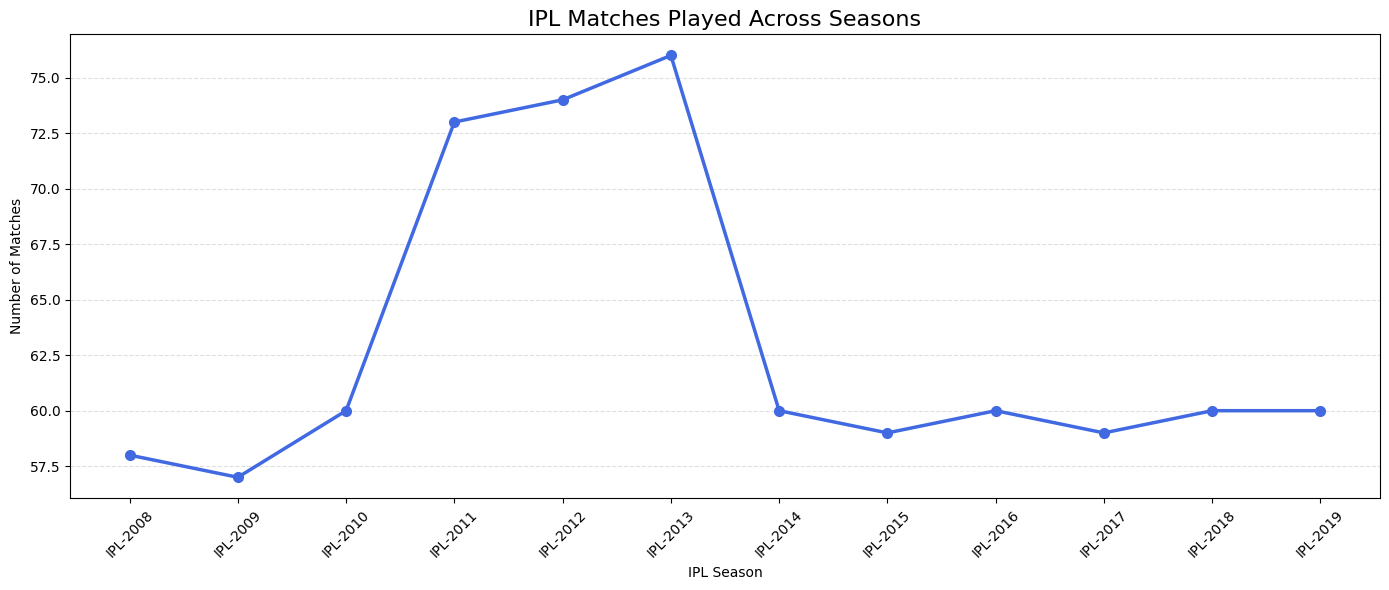

In [727]:
# Q.1 IPL matches trend across seasons :

plt.figure(figsize=(14, 6))

plt.plot(
    matches_per_season.index.astype(str),
    matches_per_season.values,
    marker='o',
    color='royalblue',
    linewidth=2.5,
    markersize=7
)

plt.title("IPL Matches Played Across Seasons", fontsize=16)
plt.xlabel("IPL Season")
plt.ylabel("Number of Matches")

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

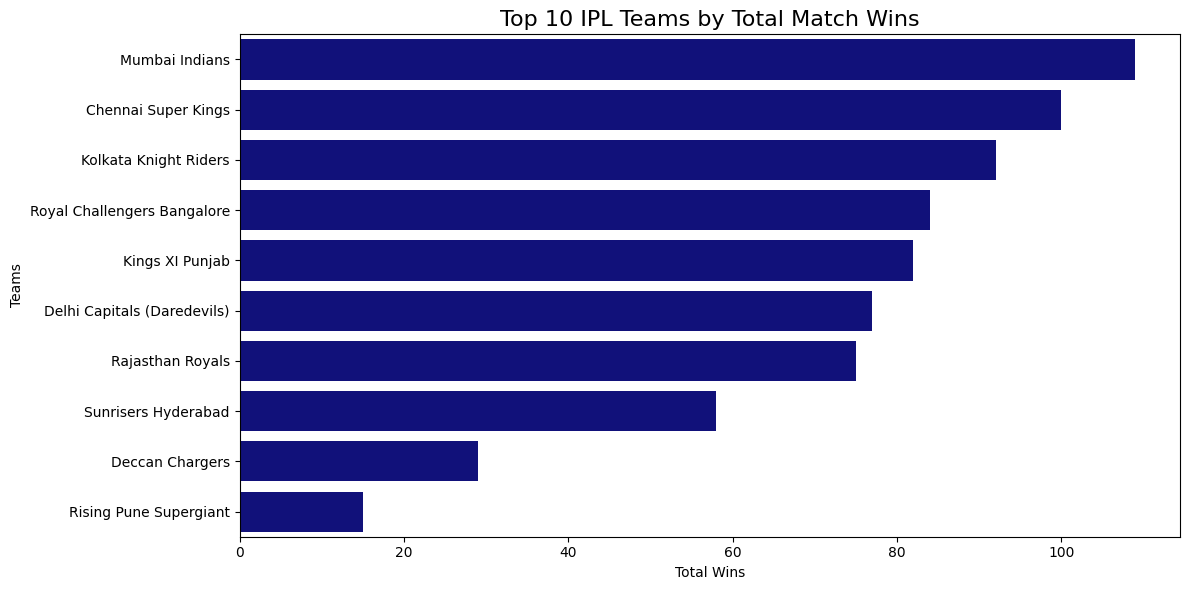

In [728]:
# Q.2 Top 10 IPL teams by total match wins :

plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_wins.head(10).values,
    y=team_wins.head(10).index,
    color='darkblue'
)

plt.title("Top 10 IPL Teams by Total Match Wins", fontsize=16)
plt.xlabel("Total Wins")
plt.ylabel("Teams")

plt.tight_layout()
plt.show()

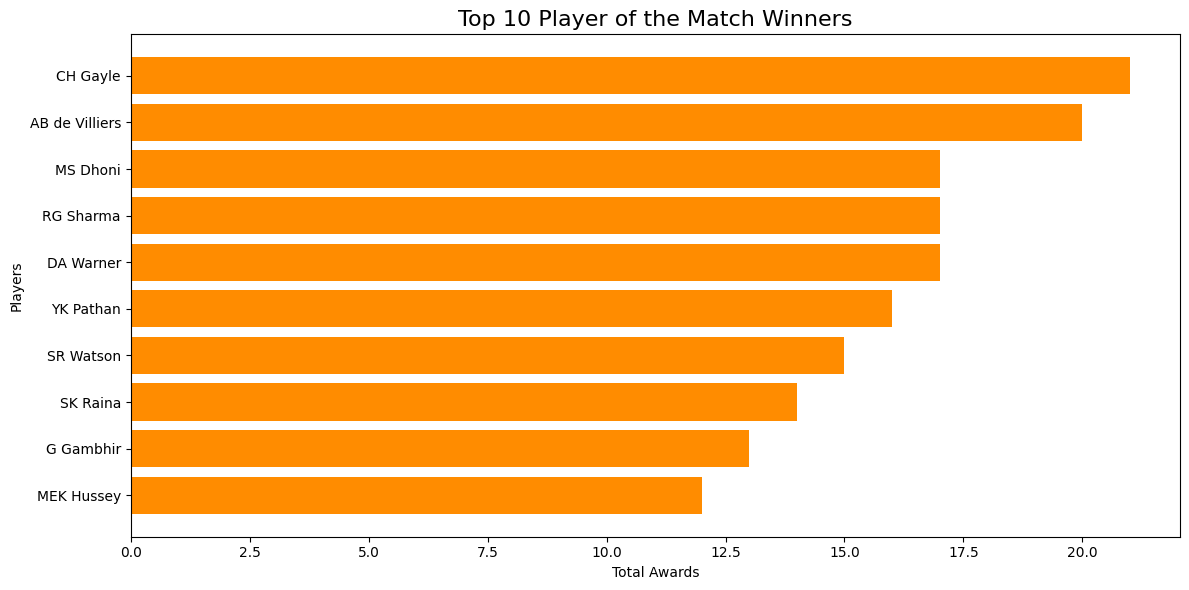

In [729]:
# Q.3 Top 10 Player of the Match winners :

plt.figure(figsize=(12, 6))

plt.barh(
    top_players.index[::-1],
    top_players.values[::-1],
    color='darkorange'
)

plt.title("Top 10 Player of the Match Winners", fontsize=16)
plt.xlabel("Total Awards")
plt.ylabel("Players")

plt.tight_layout()
plt.show()

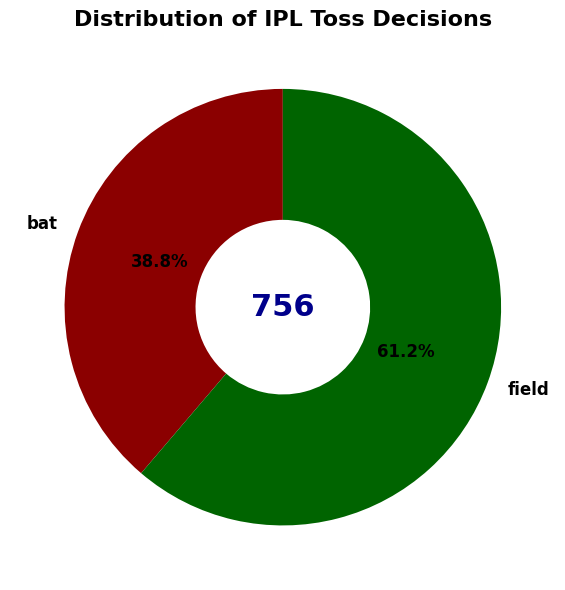

In [730]:
# Q.4 Toss decision distribution :

toss_data = df.groupby("toss_decision").size()

plt.figure(figsize=(8, 6))

plt.pie(
    toss_data,
    labels=toss_data.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.6},
    textprops={'weight': 'bold', 'fontsize': 12},
    colors=['darkred', 'darkgreen']
)

# Add total count in the centre
total_matches = toss_data.sum()

plt.text(
    0, 0,
    f'{total_matches}',
    ha='center',
    va='center',
    fontsize=22,
    fontweight='bold',
    color='darkblue'
)

plt.title(
    "Distribution of IPL Toss Decisions",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [731]:
# Q.5 Team-wise matches played vs matches won :

team_matches = pd.concat([
    df["Team1"],
    df["Team2"]
]).value_counts()

team_wins_grouped = df.groupby("winner").size()

team_summary = pd.DataFrame({
    "Matches Played": team_matches,
    "Matches Won": team_wins_grouped
}).fillna(0).reset_index()

team_summary = team_summary.rename(
    columns={"index": "Team"}
)

fig = px.scatter(
    team_summary,
    x="Matches Played",
    y="Matches Won",
    color="Team",
    hover_name="Team",
    hover_data={
        "Matches Played": True,
        "Matches Won": True
    },
    title="IPL Team Performance: Matches Played vs Matches Won"
)

fig.update_traces(
    marker=dict(size=12)
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        font=dict(size=18, color="black"),
        x=0.5
    ),
    xaxis_title="Total Matches Played",
    yaxis_title="Total Matches Won",
    showlegend=True,
    legend_title="IPL Teams"
)

fig.show()

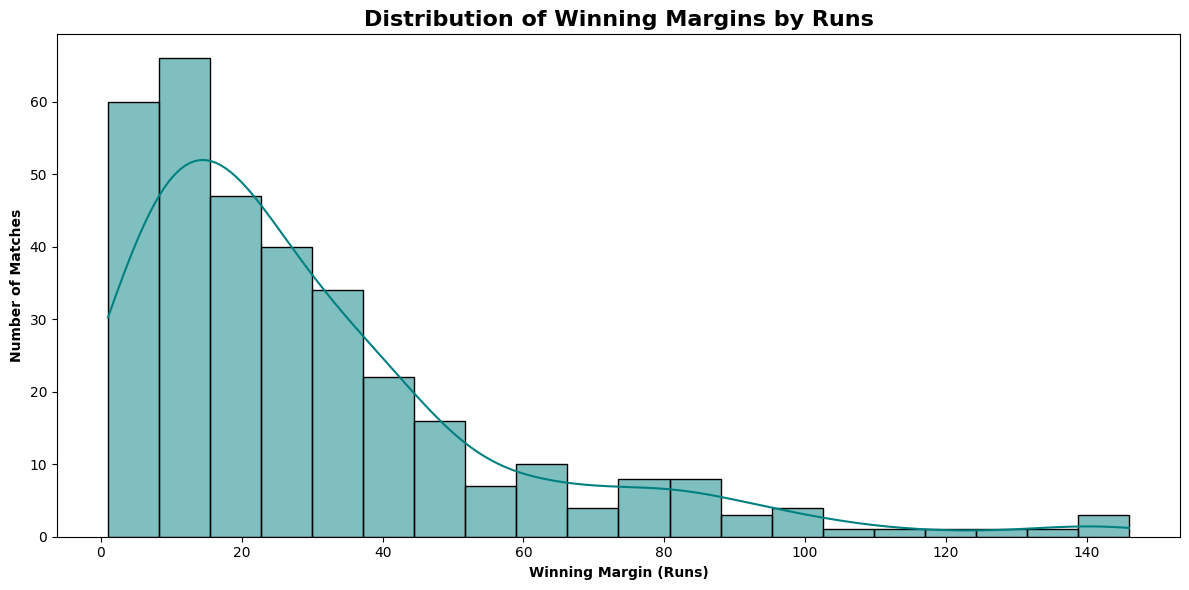

In [732]:
# Q.6 Distribution of winning margins by runs :

run_wins = df[df["win_by_runs"] > 0]

plt.figure(figsize=(12, 6))

sns.histplot(
    data=run_wins,
    x="win_by_runs",
    bins=20,
    kde=True,
    color="teal"
)

plt.title(
    "Distribution of Winning Margins by Runs",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Winning Margin (Runs)", fontweight='bold')
plt.ylabel("Number of Matches", fontweight='bold')

plt.tight_layout()
plt.show()

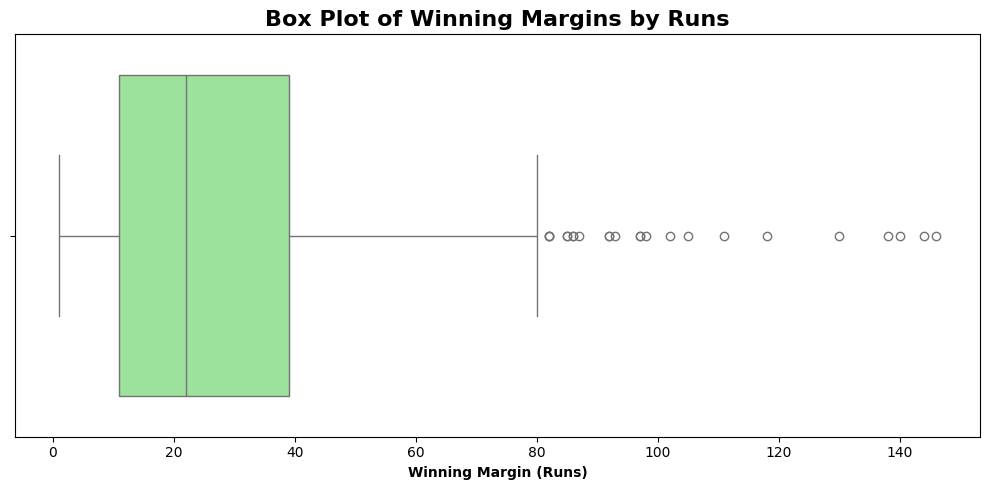

In [733]:
# Q.7 Winning margin distribution and outliers :

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df[df["win_by_runs"] > 0]["win_by_runs"],
    color='lightgreen'
)

plt.title(
    "Box Plot of Winning Margins by Runs",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Winning Margin (Runs)", fontweight='bold')

plt.tight_layout()
plt.show()

In [734]:
# Q.8 Team-wise match wins using Treemap :

team_win_data = (
    df.groupby("winner")
    .size()
    .reset_index(name="Total Wins")
    .sort_values("Total Wins", ascending=False)
)

fig = px.treemap(
    team_win_data,
    path=["winner"],
    values="Total Wins",
    color="Total Wins",
    color_continuous_scale="viridis",
    title="IPL Team-wise Match Wins"
)

fig.update_layout(
    template="plotly_white",
    title=dict(
        font=dict(size=18),
        x=0.5
    )
)

fig.show()

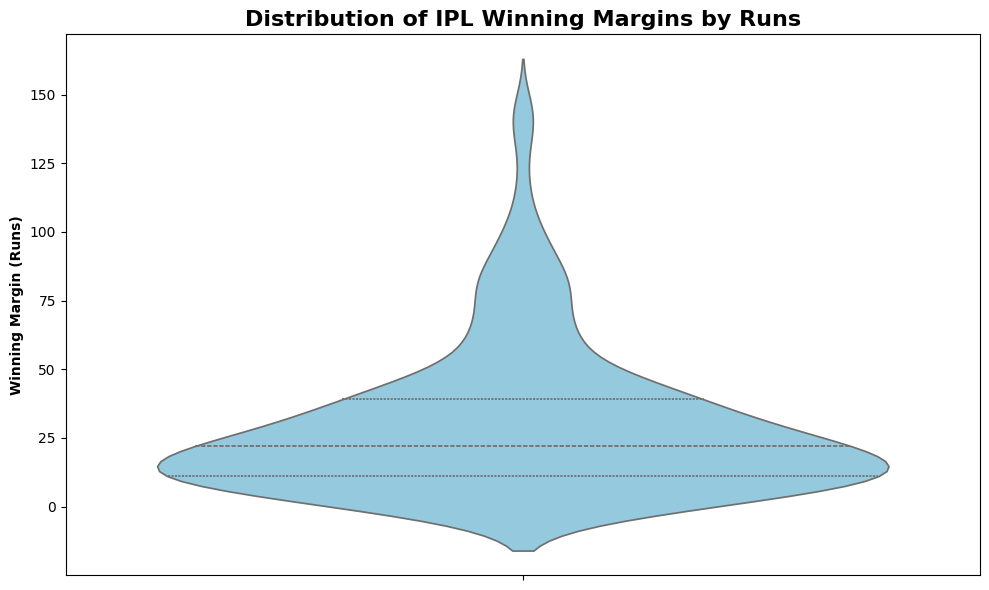

In [735]:
# Q.9 Distribution of winning margins using Violin Plot :

run_wins = df[df["win_by_runs"] > 0]

plt.figure(figsize=(10, 6))

sns.violinplot(
    y=run_wins["win_by_runs"],
    color="skyblue",
    inner="quartile"
)

plt.title(
    "Distribution of IPL Winning Margins by Runs",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Winning Margin (Runs)", fontweight="bold")

plt.tight_layout()
plt.show()

In [736]:
# Q.10 Calculate matches played by each team

matches_played = pd.concat([
    df["Team1"],
    df["Team2"]
]).value_counts()

# Calculate total wins by each team

team_wins = df["winner"].value_counts()

# Create team summary

team_summary = pd.DataFrame({
    "Matches Played": matches_played,
    "Wins": team_wins
}).fillna(0)

# Calculate win percentage

team_summary["Win %"] = (
    team_summary["Wins"] / team_summary["Matches Played"]
) * 100

# Keep teams with minimum 50 matches

team_summary = team_summary[
    team_summary["Matches Played"] >= 50
]

team_summary = team_summary.sort_values(
    by="Win %",
    ascending=True
)

team_summary

,Matches Played,Wins,Win %
Deccan Chargers,75,29,38.666667
Delhi Capitals (Daredevils),177,77,43.502825
Kings XI Punjab,176,82,46.590909
Royal Challengers Bangalore,180,84,46.666667
Rajasthan Royals,147,75,51.020408
Kolkata Knight Riders,178,92,51.685393
Sunrisers Hyderabad,108,58,53.703704
Mumbai Indians,187,109,58.288770
Chennai Super Kings,164,100,60.975610


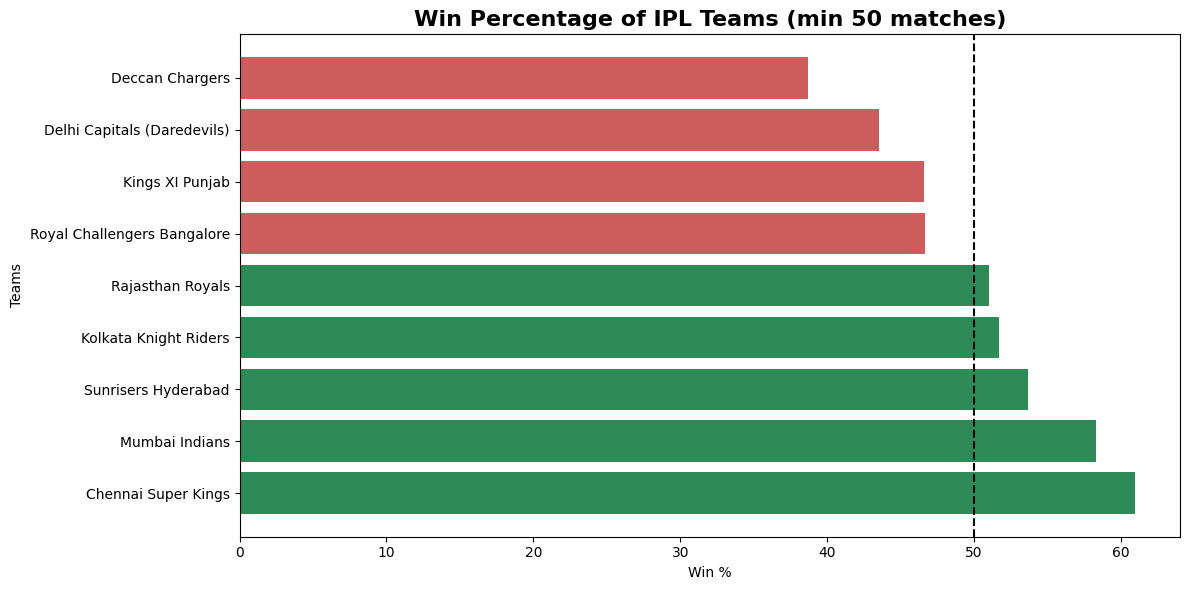

In [737]:
# Win % of teams (min 50 matches) :

plt.figure(figsize=(12, 6))

colors = ["seagreen" if x > 50 else "indianred" for x in team_summary["Win %"]]

plt.barh(team_summary.index[::-1], team_summary["Win %"][::-1], color=colors[::-1])
plt.axvline(50, color="black", linestyle="--", linewidth=1.5)

plt.title("Win Percentage of IPL Teams (min 50 matches)", fontsize=16, fontweight="bold")
plt.xlabel("Win %")
plt.ylabel("Teams")

plt.tight_layout()
plt.show()

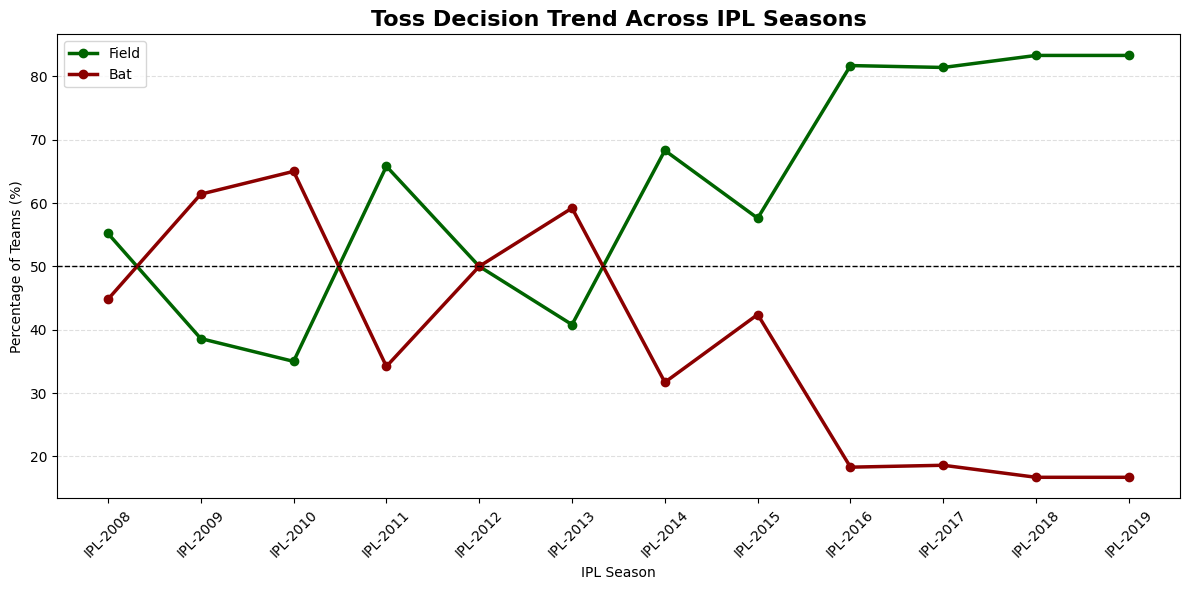

In [738]:
# Q.11 Toss decision trend across seasons :

toss_trend = (pd.crosstab(df["Season"], df["toss_decision"], normalize="index") * 100).round(1)

plt.figure(figsize=(12, 6))

plt.plot(toss_trend.index, toss_trend["field"], marker="o", linewidth=2.5,
         color="darkgreen", label="Field")
plt.plot(toss_trend.index, toss_trend["bat"], marker="o", linewidth=2.5,
         color="darkred", label="Bat")
plt.axhline(50, color="black", linestyle="--", linewidth=1)

plt.title("Toss Decision Trend Across IPL Seasons", fontsize=16, fontweight="bold")
plt.xlabel("IPL Season")
plt.ylabel("Percentage of Teams (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## **14.** **Final Summary**

This project analysed **756 IPL matches** played between 2008 and 2019 across **12 seasons, 13 teams, 33 venues, and 31 cities**. After cleaning the data, the analysis gave the following key findings.

**Data Cleaning**
- Team names were merged from **15 to 13** (Delhi Daredevils and Delhi Capitals are the same franchise, and Rising Pune Supergiant had a spelling variation).
- Venue names were merged from **41 to 33**, and `Mohali` and `Chandigarh` were treated as the same city.
- **7 missing city values** (Dubai, IPL-2014) were filled using the venue name.
- Umpire names were merged from **76 to 55**, including names that had lost characters or had typo errors.
- **2 damaged player names** were restored (`CRD Fernando` and `DP Nannes`).
- No rows were removed, and the remaining missing values (`winner` and `player_of_match` for the 4 no-result matches, and the umpire columns) are genuine.

**1. Team Performance**
- **Mumbai Indians** have the most wins (**109**), and **Chennai Super Kings** have the highest win percentage (**61.0%**) among teams with at least 50 matches.
- Only **5 teams** have a win percentage above 50%: CSK, MI, SRH, KKR, and RR.
- **RCB (46.7%), Kings XI Punjab (46.6%), and Delhi Capitals (43.5%)** have played more than 175 matches each but have won less than half of them.

**2. Seasons**
- The number of matches peaked at **76 in 2013** (more teams played from 2011 to 2013) and stabilised at about **60 matches per season** from 2014.
- Seven different teams finished with the most league wins across the 12 seasons, which shows a competitive league.

**3. Toss and Match Strategy**
- Winning the toss gives only a small advantage: toss winners won **52.3%** of matches.
- The decision matters more: teams that chose to **field won 56.3%**, while teams that chose to bat won only **45.9%**.
- **61.2%** of teams chose to field overall, and from **2016 onwards more than 80%** chose to field.
- Chasing teams won **54.6%** of matches (406 of 743 matches decided by a margin).
- **MI (57.4%) and CSK (57.3%)** are the best at defending a total, and **CSK (65.3%)** is the best at chasing. **KKR** shows the biggest gap between chasing (61.1%) and defending (41.0%).

**4. Venues and Cities**
- **M. Chinnaswamy Stadium (80 matches)** hosted the most matches, followed by Eden Gardens (77), Feroz Shah Kotla (74), and Wankhede Stadium (73).
- **Mumbai** hosted the most matches of any city (101), and the top 5 cities (Mumbai, Bangalore, Kolkata, Delhi, Hyderabad) together hosted **52.4%** of all matches.
- All 57 matches of 2009 were played in South Africa, and 20 matches of 2014 were played in the UAE.

**5. Players**
- **Chris Gayle (21)** and **AB de Villiers (20)** won the most Player of the Match awards. 14 of Gayle's 21 awards came between 2011 and 2013.
- **226 different players** won the award, and no single player has more than 2.8% of the awards. The top 10 list has no pure bowler.

**6. Winning Margins**
- The average winning margin by runs is **29.8 runs** (median 22), and the biggest win was **146 runs**

## **15.** **Business Recommendations**

Based on the analysis, the following suggestions can be made for different stakeholders.

**For Franchises and Team Management**
- Consider **fielding after winning the toss**, because teams that chose to field won **56.3%** of their matches compared to **45.9%** for teams that chose to bat. This is an association in the data, and the decision should still depend on pitch and conditions, as teams may choose to field when conditions already favour them.
- Build the squad with **strong chasers and finishers**, as chasing teams win more often (**54.6%**).
- Teams with a big gap between chasing and defending (for example **KKR: 41.0% vs 61.1%, RR: 43.3% vs 59.0%, and SRH: 47.6% vs 62.2%**) should work on their **bowling and total-defending strategy**. **Mumbai Indians and Chennai Super Kings** can be used as a model, because both are strong in defending (57%+) and chasing (59%+).
- **Royal Challengers Bangalore, Kings XI Punjab, and Delhi Capitals** have each played more than 175 matches but won less than 50% of them. These franchises should review their squad balance and auction strategy.

**For Broadcasters and Sponsors**
- Plan premium advertising and sponsorship around the **big metro cities** (Mumbai, Bangalore, Kolkata, Delhi, Hyderabad), which host **52.4%** of all matches.
- The stable schedule of about **60 matches per season** (since 2014) makes content and advertising planning easier.
- The 2009 (South Africa) and 2014 (UAE) seasons show that the league can be moved to another country and still be completed, which is useful for planning in case of disruption.

**For the League and Marketing Teams**
- Promote the **competitive balance** of the league (seven different teams topped the league stage across 12 seasons) and the **close finishes** (13% of matches).
- The Player

## **16.** **Limitations**

- The dataset contains match-level data only (no ball-by-ball data), so player-level analysis such as runs, wickets, and strike rate is not possible. Player of the Match awards are used as a proxy for player impact.
- The data covers only 2008 to 2019, so newer teams and seasons are not included.
- Win percentage includes tie and no-result matches in the total matches played.
- Some insights, such as why teams prefer fielding, are possible explanations and not proven causes.
- Some names in the data (umpires and two players) had lost characters or typo errors. These were identified and corrected during cleaning, but a few spelling issues could still remain in columns that were not checked.
- The third umpire is recorded for only 119 of the 756 matches, so umpire-level analysis was not done.

## **17.** **Conclusion**

This analysis shows that success in the IPL depends more on **team strength and match strategy** than on luck at the toss. Mumbai Indians and Chennai Super Kings stand out as the most consistent teams, both in defending and chasing. Chasing has become the preferred strategy, and the data supports it, as fielding teams and chasing teams win more often. The league is competitive, with close finishes in 13% of matches and many different match winners.

Data cleaning played an important role in this project. After merging duplicate team and venue names, the results changed noticeably: Delhi Capitals dropped from a misleading 62.5% win rate to 43.5%, and Eden Gardens was replaced by M. Chinnaswamy Stadium as the most used venue. Standardizing umpire names reduced the umpire count from 76 to 55, and damaged player names were restored. This shows that the quality of the data directly affects the quality of the insights.

## **18.** **Export Cleaned Dataset**
Export the final, validated dataset (`df`) to CSV and Excel formats after completing all cleaning rules, sanity checks, and analyses so it can be stored under `data/processed/` for downstream use and GitHub documentation.

In [739]:
from pathlib import Path

# Export cleaned DataFrame after all cleaning & analysis steps complete
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "IPL_Matches_Cleaned.csv"
xlsx_path = output_dir / "IPL_Matches_Cleaned.xlsx"

df.to_csv(csv_path, index=False)
df.to_excel(xlsx_path, index=False)

print(f"Exported cleaned dataset successfully ({len(df)} rows, {df.shape[1]} columns):")
print(f"- CSV:  {csv_path}")
print(f"- XLSX: {xlsx_path}")

Exported cleaned dataset successfully (756 rows, 18 columns):
- CSV:  data/processed/IPL_Matches_Cleaned.csv
- XLSX: data/processed/IPL_Matches_Cleaned.xlsx


In [740]:
import pandas as pd

# Reload exported CSV to verify how the saved file looks
preview_df = pd.read_csv("data/processed/IPL_Matches_Cleaned.csv")

print("Shape (rows, columns):", preview_df.shape)
print("Missing values in 'city':", preview_df["city"].isna().sum())
display(preview_df.head(5))

Shape (rows, columns): (756, 18)
Missing values in 'city': 0


,id,Season,city,date,Team1,Team2,toss_winner,toss_decision,result,dl_applied,winner,win_by_runs,win_by_wickets,player_of_match,venue,umpire1,umpire2,umpire3
0,1,IPL-2017,Hyderabad,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Royal Challengers Bangalore,field,normal,0,Sunrisers Hyderabad,35,0,Yuvraj Singh,"Rajiv Gandhi International Stadium, Uppal",Anil Dandekar,Nigel Llong,NaN
1,2,IPL-2017,Pune,2017-04-06,Mumbai Indians,Rising Pune Supergiant,Rising Pune Supergiant,field,normal,0,Rising Pune Supergiant,0,7,SPD Smith,Maharashtra Cricket Association Stadium,Nanda Kishore,Sundaram Ravi,NaN
2,3,IPL-2017,Rajkot,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,field,normal,0,Kolkata Knight Riders,0,10,CA Lynn,Saurashtra Cricket Association Stadium,Nitin Menon,CK Nandan,NaN
3,4,IPL-2017,Indore,2017-04-08,Rising Pune Supergiant,Kings XI Punjab,Kings XI Punjab,field,normal,0,Kings XI Punjab,0,6,GJ Maxwell,Holkar Cricket Stadium,Anil Chaudhary,Chettithody Shamshuddin,NaN
4,5,IPL-2017,Bangalore,2017-04-08,Royal Challengers Bangalore,Delhi Capitals (Daredevils),Royal Challengers Bangalore,bat,normal,0,Royal Challengers Bangalore,15,0,KM Jadhav,M. Chinnaswamy Stadium,NaN,NaN,NaN
